<a href="https://colab.research.google.com/github/elisabethcoller/CDD-Noise-Filtering-Algorithm/blob/main/microcontroller_algorithm/my_algorithm_11_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

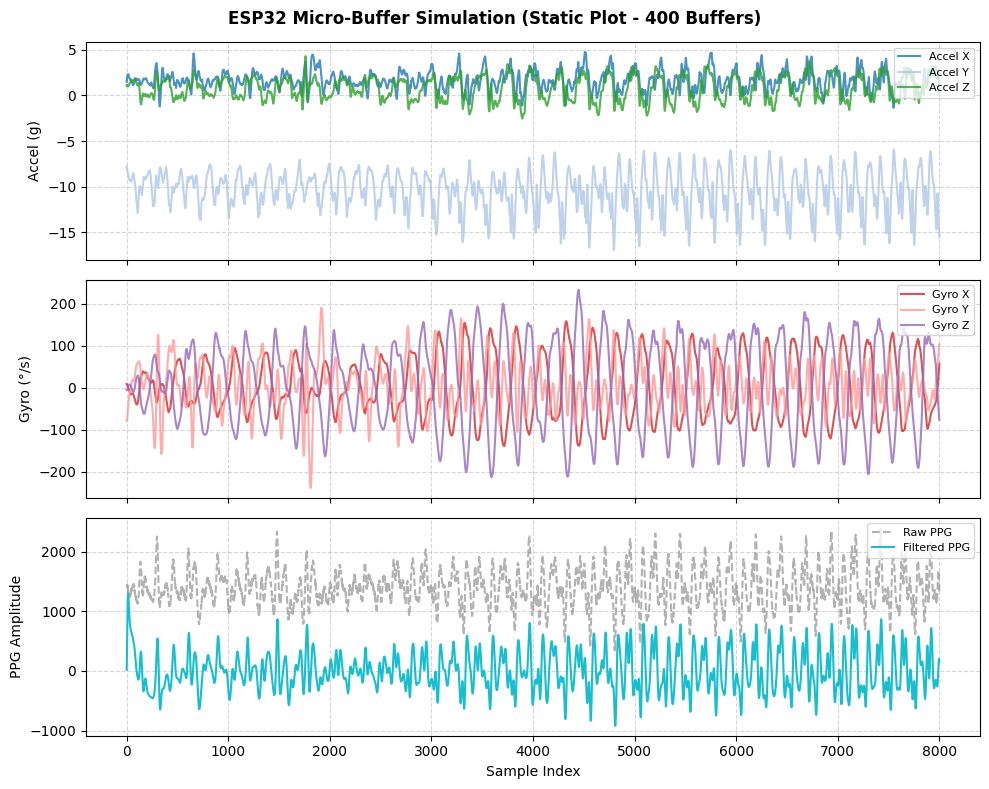

In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter_zi, lfilter

# =====================================================================
# 1. CONFIGURATION & SETUP
# =====================================================================
CONFIG = {
    "file_path": "s3.csv",              # Update with your actual CSV file path
    "sampling_rate_hz": 256.0,          # Sampling rate
    "buffer_size_samples": 20,          # Size of each micro-buffer (simulating ESP RAM chunk)
    "num_test_buffers": 400,              # Restrict simulation strictly to # buffers
    "ppg_filter": {
        "lowcut": 0.4,
        "highcut": 10.0,
        "order": 2
    },
    # Column mapping based on your provided schema
    "column_mapping": {
        "time": "sample_times_for_all_signals_apart_from_ecg",
        "ppg": "wrist_ppg",
        "gyro_x": "wrist_gyro_x",
        "gyro_y": "wrist_gyro_y",
        "gyro_z": "wrist_gyro_z",
        "accel_x": "wrist_low_noise_accelerometer_x",
        "accel_y": "wrist_low_noise_accelerometer_y",
        "accel_z": "wrist_low_noise_accelerometer_z"
    }
}

# =====================================================================
# 2. LOAD DATA & SLICE TO 5 BUFFERS
# =====================================================================
path = CONFIG["file_path"]
if not os.path.exists(path):
    raise FileNotFoundError(f"[!] Error: File '{path}' not found.")

df = pd.read_csv(path)
cols = CONFIG["column_mapping"]
buffer_size = CONFIG["buffer_size_samples"]
total_samples_needed = buffer_size * CONFIG["num_test_buffers"]

if len(df) < total_samples_needed:
    total_samples_needed = len(df)

df_subset = df.iloc[:total_samples_needed].copy()

times = df_subset[cols["time"]].values
raw_ppg = df_subset[cols["ppg"]].values
accel = df_subset[[cols["accel_x"], cols["accel_y"], cols["accel_z"]]].values
gyro = df_subset[[cols["gyro_x"], cols["gyro_y"], cols["gyro_z"]]].values

# =====================================================================
# 3. FILTER SETUP & BUFFERED PROCESSING LOOP
# =====================================================================
fs = CONFIG["sampling_rate_hz"]
low = CONFIG["ppg_filter"]["lowcut"]
high = CONFIG["ppg_filter"]["highcut"]
order = CONFIG["ppg_filter"]["order"]

nyq = 0.5 * fs
b, a = butter(order, [low / nyq, high / nyq], btype='band')

# Initialize stateful filter delay registers (zi)
zi_state = lfilter_zi(b, a) * 0

# Containers for processed data
x_data, raw_ppg_all, clean_ppg_all = [], [], []
ax_all, ay_all, az_all = [], [], []
gx_all, gy_all, gz_all = [], [], []

# Simulate the ESP pulling data buffer-by-buffer
for frame_idx in range(CONFIG["num_test_buffers"]):
    start_idx = frame_idx * buffer_size
    end_idx = start_idx + buffer_size

    if start_idx >= len(df_subset):
        break

    chunk_t = range(start_idx, end_idx)
    chunk_accel = accel[start_idx:end_idx]
    chunk_gyro = gyro[start_idx:end_idx]
    chunk_raw_ppg = raw_ppg[start_idx:end_idx]

    # Apply stateful causal filter per buffer chunk (preserving zi_state continuity)
    chunk_clean_ppg, zi_state = lfilter(b, a, chunk_raw_ppg, zi=zi_state)

    # Accumulate
    x_data.extend(chunk_t)
    raw_ppg_all.extend(chunk_raw_ppg)
    clean_ppg_all.extend(chunk_clean_ppg)

    ax_all.extend(chunk_accel[:, 0])
    ay_all.extend(chunk_accel[:, 1])
    az_all.extend(chunk_accel[:, 2])

    gx_all.extend(chunk_gyro[:, 0])
    gy_all.extend(chunk_gyro[:, 1])
    gz_all.extend(chunk_gyro[:, 2])

   #print(f"[Buffer {frame_idx + 1}/{CONFIG['num_test_buffers']}] Processed indices {start_idx} to {end_idx}")

# =====================================================================
# 4. PLOTTING
# =====================================================================
fig, (ax_accel, ax_gyro, ax_ppg) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
fig.suptitle(f"ESP32 Micro-Buffer Simulation (Static Plot - {CONFIG['num_test_buffers']} Buffers)", fontsize=12, fontweight='bold')

# Accelerometer
ax_accel.plot(x_data, ax_all, label='Accel X', color='#1f77b4', alpha=0.8)
ax_accel.plot(x_data, ay_all, label='Accel Y', color='#aec7e8', alpha=0.8)
ax_accel.plot(x_data, az_all, label='Accel Z', color='#2ca02c', alpha=0.8)
ax_accel.set_ylabel("Accel (g)")
ax_accel.legend(loc='upper right', fontsize=8)
ax_accel.grid(True, linestyle='--', alpha=0.5)

# Gyroscope
ax_gyro.plot(x_data, gx_all, label='Gyro X', color='#d62728', alpha=0.8)
ax_gyro.plot(x_data, gy_all, label='Gyro Y', color='#ff9896', alpha=0.8)
ax_gyro.plot(x_data, gz_all, label='Gyro Z', color='#9467bd', alpha=0.8)
ax_gyro.set_ylabel("Gyro (°/s)")
ax_gyro.legend(loc='upper right', fontsize=8)
ax_gyro.grid(True, linestyle='--', alpha=0.5)

# PPG (Raw vs Clean)
ax_ppg.plot(x_data, raw_ppg_all, label='Raw PPG', color='gray', alpha=0.6, linestyle='--')
ax_ppg.plot(x_data, clean_ppg_all, label='Filtered PPG', color='#17becf', linewidth=1.5)
ax_ppg.set_ylabel("PPG Amplitude")
ax_ppg.set_xlabel("Sample Index")
ax_ppg.legend(loc='upper right', fontsize=8)
ax_ppg.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

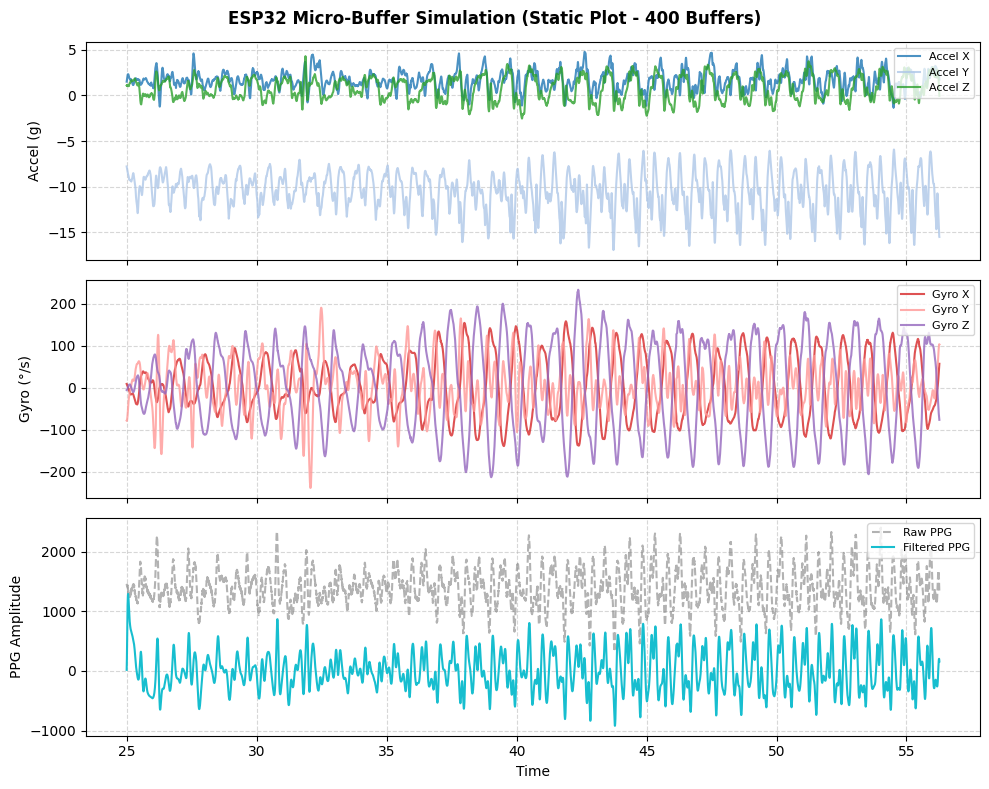

In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter_zi, lfilter

# =====================================================================
# 1. CONFIGURATION & SETUP
# =====================================================================
CONFIG = {
    "file_path": "s3.csv",              # Update with your actual CSV file path
    "sampling_rate_hz": 256.0,          # Sampling rate
    "buffer_size_samples": 20,          # Size of each micro-buffer (simulating ESP RAM chunk)
    "num_test_buffers": 400,              # Restrict simulation strictly to # buffers
    "ppg_filter": {
        "lowcut": 0.4,
        "highcut": 10.0,
        "order": 2
    },
    # Column mapping based on your provided schema
    "column_mapping": {
        "time": "sample_times_for_all_signals_apart_from_ecg",
        "ppg": "wrist_ppg",
        "gyro_x": "wrist_gyro_x",
        "gyro_y": "wrist_gyro_y",
        "gyro_z": "wrist_gyro_z",
        "accel_x": "wrist_low_noise_accelerometer_x",
        "accel_y": "wrist_low_noise_accelerometer_y",
        "accel_z": "wrist_low_noise_accelerometer_z"
    }
}

# =====================================================================
# 2. LOAD DATA & SLICE TO 5 BUFFERS
# =====================================================================
path = CONFIG["file_path"]
if not os.path.exists(path):
    raise FileNotFoundError(f"[!] Error: File '{path}' not found.")

df = pd.read_csv(path)
cols = CONFIG["column_mapping"]
buffer_size = CONFIG["buffer_size_samples"]
total_samples_needed = buffer_size * CONFIG["num_test_buffers"]

if len(df) < total_samples_needed:
    total_samples_needed = len(df)

df_subset = df.iloc[:total_samples_needed].copy()

times = df_subset[cols["time"]].values
raw_ppg = df_subset[cols["ppg"]].values
accel = df_subset[[cols["accel_x"], cols["accel_y"], cols["accel_z"]]].values
gyro = df_subset[[cols["gyro_x"], cols["gyro_y"], cols["gyro_z"]]].values

# =====================================================================
# 3. FILTER SETUP & BUFFERED PROCESSING LOOP
# =====================================================================
fs = CONFIG["sampling_rate_hz"]
low = CONFIG["ppg_filter"]["lowcut"]
high = CONFIG["ppg_filter"]["highcut"]
order = CONFIG["ppg_filter"]["order"]

nyq = 0.5 * fs
b, a = butter(order, [low / nyq, high / nyq], btype='band')

# Initialize stateful filter delay registers (zi)
zi_state = lfilter_zi(b, a) * 0

# Containers for processed data
time_data, raw_ppg_all, clean_ppg_all = [], [], []
ax_all, ay_all, az_all = [], [], []
gx_all, gy_all, gz_all = [], [], []

# Simulate the ESP pulling data buffer-by-buffer
for frame_idx in range(CONFIG["num_test_buffers"]):
    start_idx = frame_idx * buffer_size
    end_idx = min(start_idx + buffer_size, len(df_subset))

    if start_idx >= len(df_subset):
        break

    chunk_t = times[start_idx:end_idx]
    chunk_accel = accel[start_idx:end_idx]
    chunk_gyro = gyro[start_idx:end_idx]
    chunk_raw_ppg = raw_ppg[start_idx:end_idx]

    # Apply stateful causal filter per buffer chunk (preserving zi_state continuity)
    chunk_clean_ppg, zi_state = lfilter(b, a, chunk_raw_ppg, zi=zi_state)

    # Accumulate
    time_data.extend(chunk_t)
    raw_ppg_all.extend(chunk_raw_ppg)
    clean_ppg_all.extend(chunk_clean_ppg)

    ax_all.extend(chunk_accel[:, 0])
    ay_all.extend(chunk_accel[:, 1])
    az_all.extend(chunk_accel[:, 2])

    gx_all.extend(chunk_gyro[:, 0])
    gy_all.extend(chunk_gyro[:, 1])
    gz_all.extend(chunk_gyro[:, 2])

   #print(f"[Buffer {frame_idx + 1}/{CONFIG['num_test_buffers']}] Processed indices {start_idx} to {end_idx}")

# =====================================================================
# 4. PLOTTING
# =====================================================================
fig, (ax_accel, ax_gyro, ax_ppg) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
fig.suptitle(f"ESP32 Micro-Buffer Simulation (Static Plot - {CONFIG['num_test_buffers']} Buffers)", fontsize=12, fontweight='bold')

# Accelerometer
ax_accel.plot(time_data, ax_all, label='Accel X', color='#1f77b4', alpha=0.8)
ax_accel.plot(time_data, ay_all, label='Accel Y', color='#aec7e8', alpha=0.8)
ax_accel.plot(time_data, az_all, label='Accel Z', color='#2ca02c', alpha=0.8)
ax_accel.set_ylabel("Accel (g)")
ax_accel.legend(loc='upper right', fontsize=8)
ax_accel.grid(True, linestyle='--', alpha=0.5)

# Gyroscope
ax_gyro.plot(time_data, gx_all, label='Gyro X', color='#d62728', alpha=0.8)
ax_gyro.plot(time_data, gy_all, label='Gyro Y', color='#ff9896', alpha=0.8)
ax_gyro.plot(time_data, gz_all, label='Gyro Z', color='#9467bd', alpha=0.8)
ax_gyro.set_ylabel("Gyro (°/s)")
ax_gyro.legend(loc='upper right', fontsize=8)
ax_gyro.grid(True, linestyle='--', alpha=0.5)

# PPG (Raw vs Clean)
ax_ppg.plot(time_data, raw_ppg_all, label='Raw PPG', color='gray', alpha=0.6, linestyle='--')
ax_ppg.plot(time_data, clean_ppg_all, label='Filtered PPG', color='#17becf', linewidth=1.5)
ax_ppg.set_ylabel("PPG Amplitude")
ax_ppg.set_xlabel("Time")
ax_ppg.legend(loc='upper right', fontsize=8)
ax_ppg.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


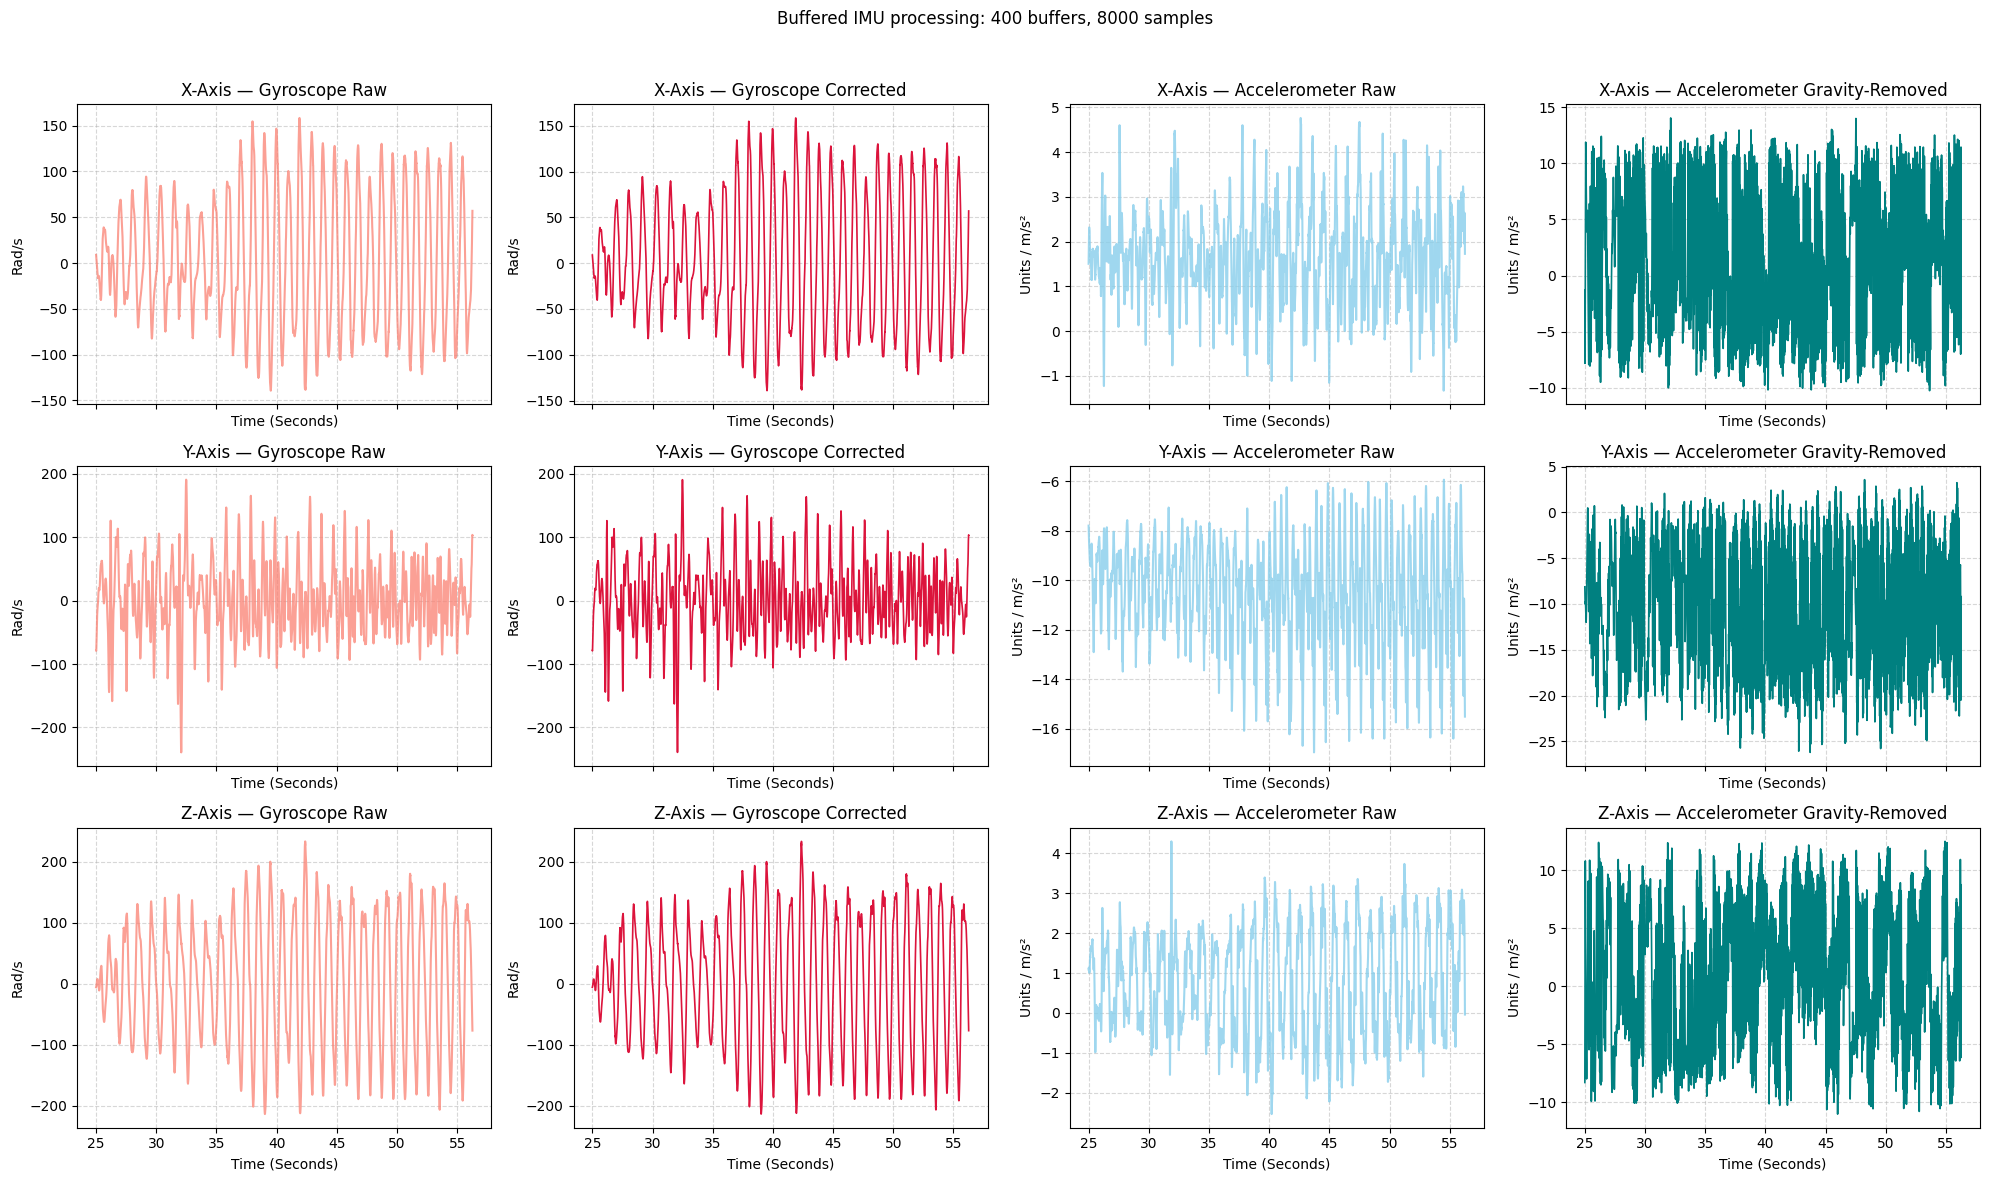

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# Change run parameters here.
SETTINGS = {
    "file_path": "s3.csv",
    "buffer_size_samples": 20,
    "num_test_buffers": 400,  # Set to None to process the entire file.
    "sampling_rate_hz": 256.0,  # Used if the time column cannot determine dt.
    "time_column": "sample_times_for_all_signals_apart_from_ecg",
    "gyro_columns": ["wrist_gyro_x", "wrist_gyro_y", "wrist_gyro_z"],
    "accel_columns": [
        "wrist_low_noise_accelerometer_x",
        "wrist_low_noise_accelerometer_y",
        "wrist_low_noise_accelerometer_z",
    ],
    "gravity_magnitude": 9.81,
    "initial_gyro_bias": [0.0, 0.0, 0.0],
    "bias_learning_rate": 0.001,
}


def rot_matrix_from_quaternion(q):
    """Compute a rotation matrix from quaternion [w, x, y, z]."""
    w, x, y, z = q
    return np.array([
        [1 - 2 * (y**2 + z**2), 2 * (x * y - z * w), 2 * (x * z + y * w)],
        [2 * (x * y + z * w), 1 - 2 * (x**2 + z**2), 2 * (y * z - x * w)],
        [2 * (x * z - y * w), 2 * (y * z + x * w), 1 - 2 * (x**2 + y**2)],
    ])


def run_csv_imu_fusion(settings=SETTINGS):
    df = pd.read_csv(settings["file_path"])
    time_col = settings["time_column"]
    gyro_cols = settings["gyro_columns"]
    accel_cols = settings["accel_columns"]

    # Restrict the data to the requested number of buffers before processing
    # or plotting. None means all rows in the CSV.
    buffer_size = int(settings["buffer_size_samples"])
    if buffer_size <= 0:
        raise ValueError("buffer_size_samples must be greater than zero")

    requested_buffers = settings["num_test_buffers"]
    if requested_buffers is not None and requested_buffers <= 0:
        raise ValueError("num_test_buffers must be greater than zero or None")

    samples_to_process = len(df)
    if requested_buffers is not None:
        samples_to_process = min(len(df), buffer_size * int(requested_buffers))
    df = df.iloc[:samples_to_process].copy()

    t = df[time_col].to_numpy()
    gyro_raw = df[gyro_cols].to_numpy(dtype=float)
    accel_raw = df[accel_cols].to_numpy(dtype=float)
    num_samples = len(df)

    if num_samples == 0:
        raise ValueError("The selected file or buffer range contains no samples")

    # Use the actual time spacing where possible; fall back to the configured rate.
    fallback_dt = 1.0 / float(settings["sampling_rate_hz"])
    if fallback_dt <= 0:
        raise ValueError("sampling_rate_hz must be greater than zero")
    time_diffs = np.diff(t.astype(float)) if num_samples > 1 else np.array([])
    valid_diffs = time_diffs[np.isfinite(time_diffs) & (time_diffs > 0)]
    default_dt = float(np.median(valid_diffs)) if len(valid_diffs) else fallback_dt

    g_global = np.array([0.0, 0.0, float(settings["gravity_magnitude"])])
    gain_bias = float(settings["bias_learning_rate"])
    q_est = np.array([1.0, 0.0, 0.0, 0.0])
    bias_est = np.asarray(settings["initial_gyro_bias"], dtype=float).copy()
    gyro_corrected = np.zeros_like(gyro_raw)
    dynamic_accel = np.zeros_like(accel_raw)

    # Process sequential chunks, retaining orientation and bias estimates across
    # buffer boundaries to simulate streaming memory.
    num_buffers = (num_samples + buffer_size - 1) // buffer_size
    for buffer_idx in range(num_buffers):
        start_idx = buffer_idx * buffer_size
        end_idx = min(start_idx + buffer_size, num_samples)
        chunk_gyro = gyro_raw[start_idx:end_idx]
        chunk_accel = accel_raw[start_idx:end_idx]

        for i in range(len(chunk_gyro)):
            global_i = start_idx + i
            omega_unbiased = chunk_gyro[i] - bias_est
            gyro_corrected[global_i] = omega_unbiased

            dt = default_dt
            if global_i > 0 and np.isfinite(float(t[global_i])) and np.isfinite(float(t[global_i - 1])):
                candidate_dt = float(t[global_i]) - float(t[global_i - 1])
                if candidate_dt > 0:
                    dt = candidate_dt

            omega_step = omega_unbiased * dt
            angle = np.linalg.norm(omega_step)
            if angle > 1e-8:
                axis = omega_step / angle
                half_angle = angle / 2.0
                dq = np.array([np.cos(half_angle), *(axis * np.sin(half_angle))])
                w1, x1, y1, z1 = q_est
                w2, x2, y2, z2 = dq
                q_est = np.array([
                    w1 * w2 - x1 * x2 - y1 * y2 - z1 * z2,
                    w1 * x2 + x1 * w2 + y1 * z2 - z1 * y2,
                    w1 * y2 - x1 * z2 + y1 * w2 + z1 * x2,
                    w1 * z2 + x1 * y2 - y1 * x2 + z1 * w2,
                ])
                q_est /= np.linalg.norm(q_est)

            R_est = rot_matrix_from_quaternion(q_est)
            g_expected = R_est.T @ g_global
            a_meas = chunk_accel[i]

            a_mag = np.linalg.norm(a_meas)
            if 0.5 * settings["gravity_magnitude"] < a_mag < 1.5 * settings["gravity_magnitude"]:
                error_axis = np.cross(
                    a_meas / a_mag,
                    g_expected / np.linalg.norm(g_expected),
                )
                bias_est += error_axis * gain_bias

            dynamic_accel[global_i] = a_meas - g_expected

    # Processed gyroscope and accelerometer data into individual panels.
    fig, axes = plt.subplots(3, 4, figsize=(20, 12), sharex=True)
    axis_labels = ["X-Axis", "Y-Axis", "Z-Axis"]
    column_titles = [
        "Gyroscope Raw",
        "Gyroscope Corrected",
        "Accelerometer Raw",
        "Accelerometer Gravity-Removed",
    ]

    for i, axis_label in enumerate(axis_labels):
        axes[i, 0].plot(t, gyro_raw[:, i], color="salmon", alpha=0.75)
        axes[i, 1].plot(t, gyro_corrected[:, i], color="crimson", linewidth=1.2)
        axes[i, 2].plot(t, accel_raw[:, i], color="skyblue", alpha=0.8)
        axes[i, 3].plot(t, dynamic_accel[:, i], color="teal", linewidth=1.2)

        for j, title in enumerate(column_titles):
            axes[i, j].set_title(f"{axis_label} — {title}")
            axes[i, j].grid(True, linestyle="--", alpha=0.5)
            axes[i, j].set_xlabel("Time (Seconds)")

        axes[i, 0].set_ylabel("Rad/s")
        axes[i, 1].set_ylabel("Rad/s")
        axes[i, 2].set_ylabel("Units / m/s²")
        axes[i, 3].set_ylabel("Units / m/s²")

    fig.suptitle(f"Buffered IMU processing: {num_buffers} buffers, {num_samples} samples")
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


if __name__ == "__main__":
    run_csv_imu_fusion()

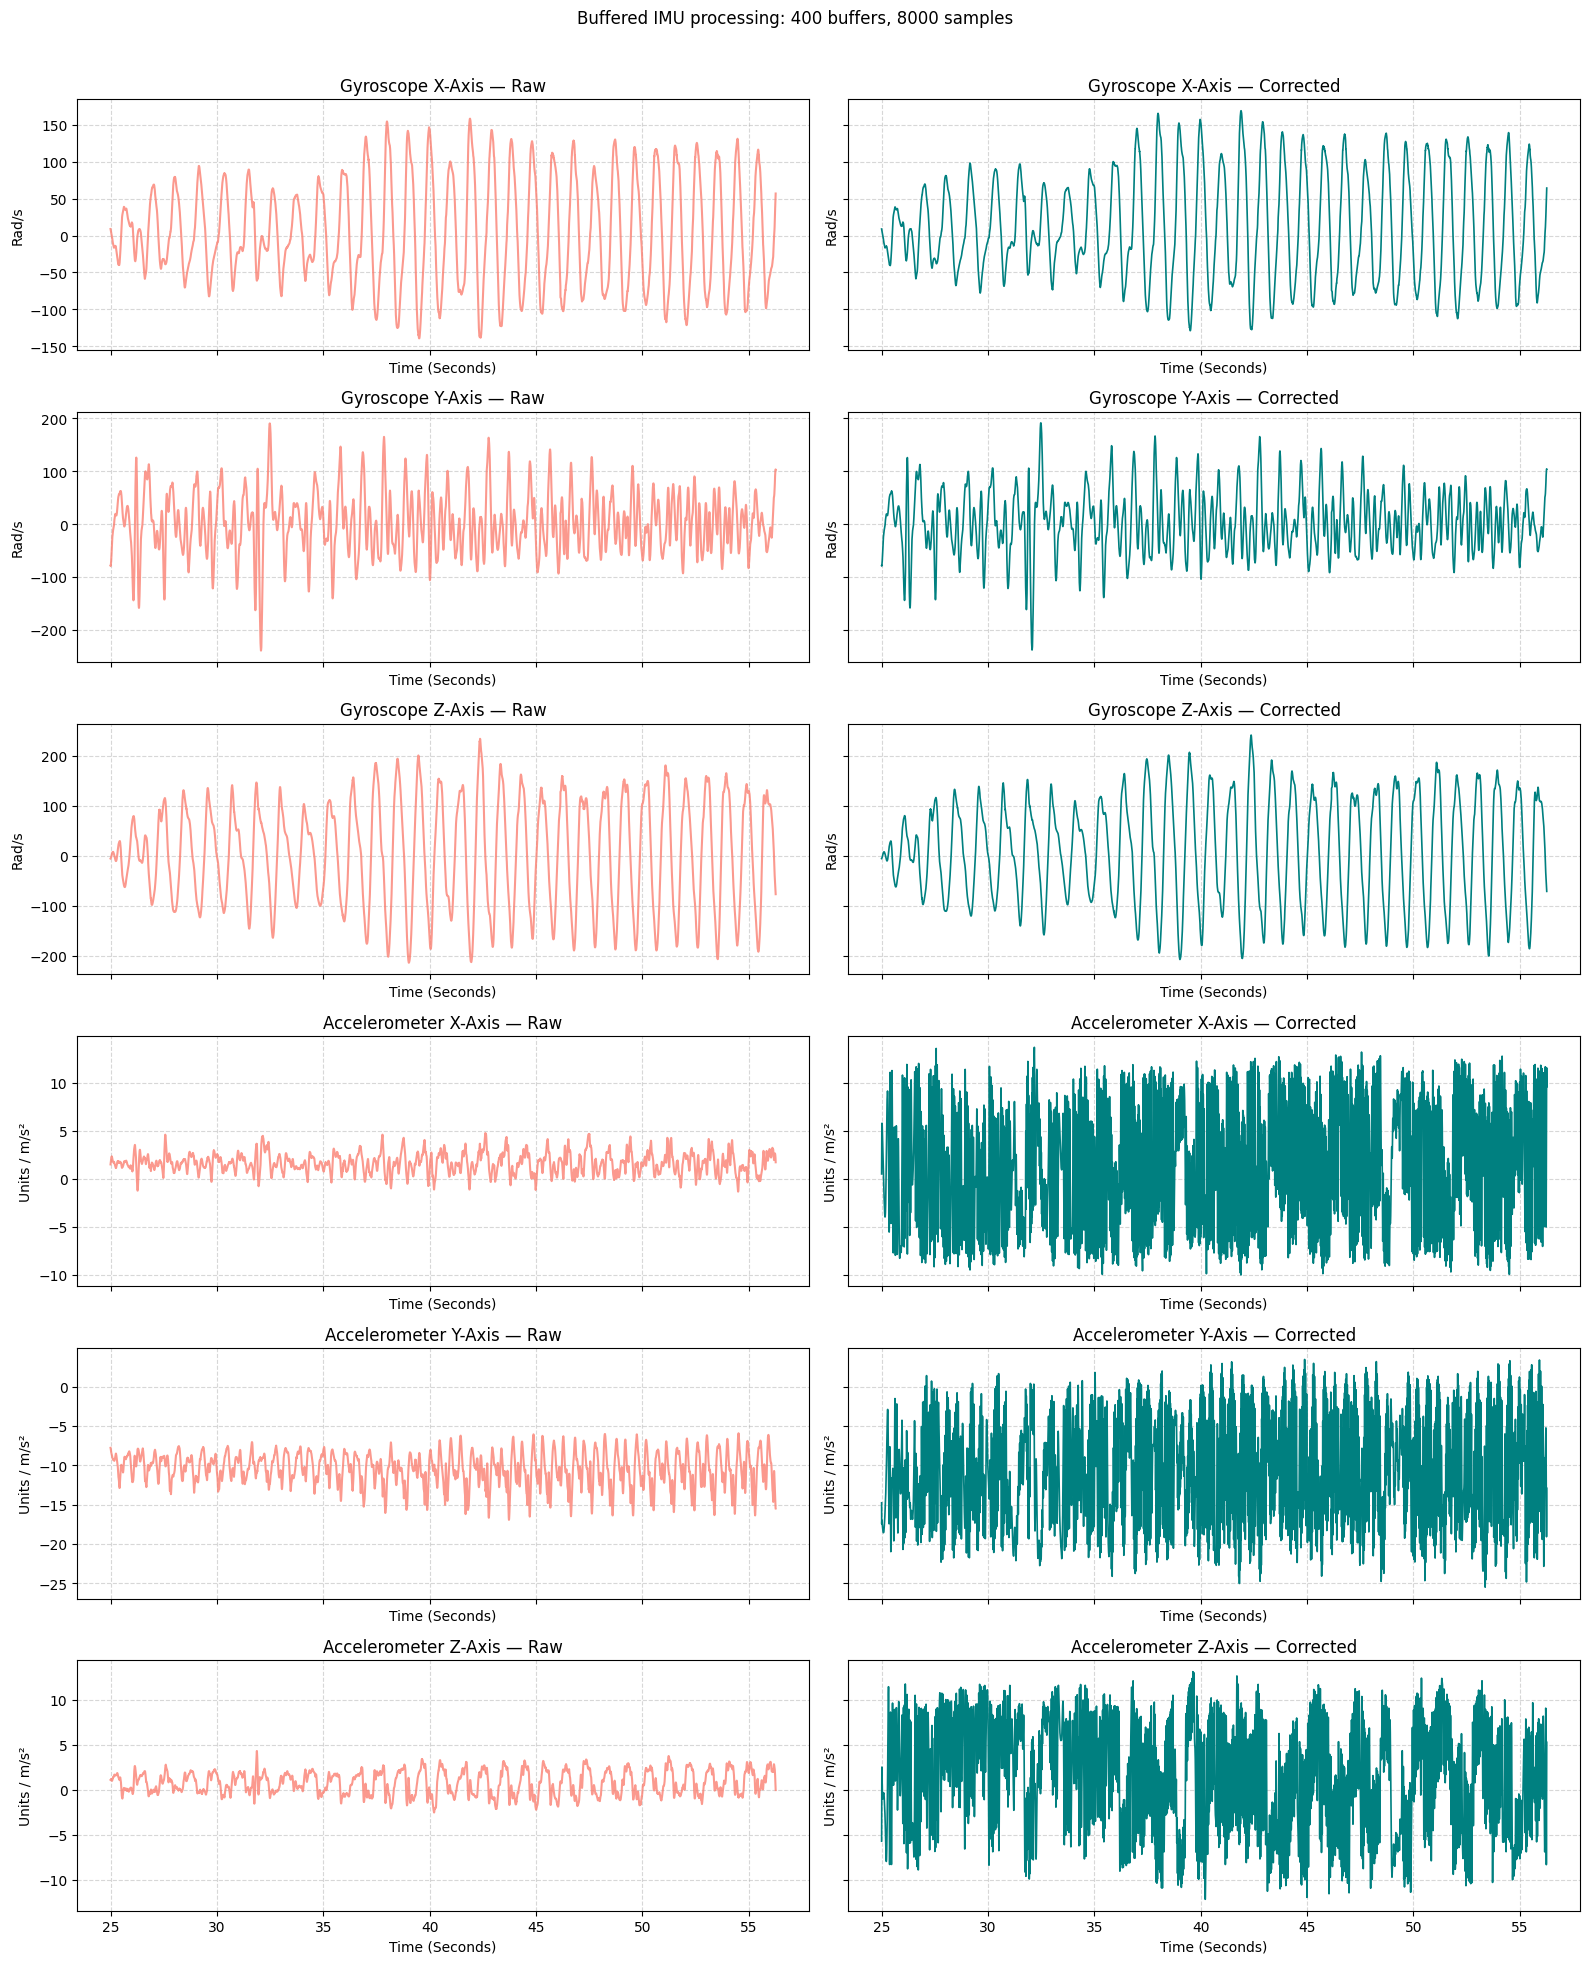

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# Change run parameters here.
SETTINGS = {
    "file_path": "s3.csv",
    "buffer_size_samples": 20,
    "num_test_buffers": 400,  # Set to None to process the entire file.
    "sampling_rate_hz": 256.0,  # Used if the time column cannot determine dt.
    "time_column": "sample_times_for_all_signals_apart_from_ecg",
    "gyro_columns": ["wrist_gyro_x", "wrist_gyro_y", "wrist_gyro_z"],
    "accel_columns": [
        "wrist_low_noise_accelerometer_x",
        "wrist_low_noise_accelerometer_y",
        "wrist_low_noise_accelerometer_z",
    ],
    "gravity_magnitude": 9.81,
    # IMU-filter-like noise variances; tune these for your sensor.
    "accelerometer_noise": 0.02,
    "gyroscope_noise": 1.0e-5,
    "gyroscope_drift_noise": 1.0e-8,
    "linear_acceleration_noise": 0.1,
    "linear_acceleration_decay": 0.5,
    "initial_orientation_wxyz": [1.0, 0.0, 0.0, 0.0],
    "initial_gyro_bias": [0.0, 0.0, 0.0],
}


def rot_matrix_from_quaternion(q):
    """Compute a rotation matrix from quaternion [w, x, y, z]."""
    w, x, y, z = q
    return np.array([
        [1 - 2 * (y**2 + z**2), 2 * (x * y - z * w), 2 * (x * z + y * w)],
        [2 * (x * y + z * w), 1 - 2 * (x**2 + z**2), 2 * (y * z - x * w)],
        [2 * (x * z - y * w), 2 * (y * z + x * w), 1 - 2 * (x**2 + y**2)],
    ])


def quaternion_multiply(q1, q2):
    """Hamilton product for quaternions stored as [w, x, y, z]."""
    w1, x1, y1, z1 = q1
    w2, x2, y2, z2 = q2
    return np.array([
        w1*w2 - x1*x2 - y1*y2 - z1*z2,
        w1*x2 + x1*w2 + y1*z2 - z1*y2,
        w1*y2 - x1*z2 + y1*w2 + z1*x2,
        w1*z2 + x1*y2 - y1*x2 + z1*w2,
    ])


def quaternion_from_rotation_vector(rotation_vector):
    """Convert a 3D rotation vector in radians to [w, x, y, z]."""
    angle = np.linalg.norm(rotation_vector)
    if angle < 1e-12:
        return np.array([1.0, 0.0, 0.0, 0.0])
    return np.r_[np.cos(angle / 2),
                 rotation_vector / angle * np.sin(angle / 2)]


def run_csv_imu_fusion(settings=SETTINGS):
    df = pd.read_csv(settings["file_path"])
    time_col = settings["time_column"]
    gyro_cols = settings["gyro_columns"]
    accel_cols = settings["accel_columns"]

    # Restrict the data to the requested number of buffers before processing
    # or plotting. None means all rows in the CSV.
    buffer_size = int(settings["buffer_size_samples"])
    if buffer_size <= 0:
        raise ValueError("buffer_size_samples must be greater than zero")

    requested_buffers = settings["num_test_buffers"]
    if requested_buffers is not None and requested_buffers <= 0:
        raise ValueError("num_test_buffers must be greater than zero or None")

    samples_to_process = len(df)
    if requested_buffers is not None:
        samples_to_process = min(len(df), buffer_size * int(requested_buffers))
    df = df.iloc[:samples_to_process].copy()

    t = df[time_col].to_numpy()
    gyro_raw = df[gyro_cols].to_numpy(dtype=float)
    accel_raw = df[accel_cols].to_numpy(dtype=float)
    num_samples = len(df)

    if num_samples == 0:
        raise ValueError("The selected file or buffer range contains no samples")

    # Use the actual time spacing where possible; fall back to the configured rate.
    fallback_dt = 1.0 / float(settings["sampling_rate_hz"])
    if fallback_dt <= 0:
        raise ValueError("sampling_rate_hz must be greater than zero")
    time_diffs = np.diff(t.astype(float)) if num_samples > 1 else np.array([])
    valid_diffs = time_diffs[np.isfinite(time_diffs) & (time_diffs > 0)]
    default_dt = float(np.median(valid_diffs)) if len(valid_diffs) else fallback_dt

    g_global = np.array([0.0, 0.0, float(settings["gravity_magnitude"])])
    q_est = np.asarray(settings["initial_orientation_wxyz"], dtype=float).copy()
    q_norm = np.linalg.norm(q_est)
    if q_norm == 0:
        raise ValueError("initial_orientation_wxyz cannot be a zero quaternion")
    q_est /= q_norm
    bias_est = np.asarray(settings["initial_gyro_bias"], dtype=float).copy()
    gyro_corrected = np.zeros_like(gyro_raw)
    dynamic_accel = np.zeros_like(accel_raw)
    linear_accel_est = np.zeros(3)

    # Nine-state indirect EKF covariance: orientation error (3), gyro-bias
    # error (3), and linear-acceleration error (3).
    P = np.diag([0.1] * 3 + [0.01] * 3 + [1.0] * 3)
    accel_noise = float(settings["accelerometer_noise"])
    gyro_noise = float(settings["gyroscope_noise"])
    gyro_drift_noise = float(settings["gyroscope_drift_noise"])
    lin_accel_noise = float(settings["linear_acceleration_noise"])
    lin_accel_decay = float(settings["linear_acceleration_decay"])

    # Process sequential chunks, retaining orientation, bias, linear-acceleration
    # state, and EKF covariance across buffer boundaries.
    num_buffers = (num_samples + buffer_size - 1) // buffer_size
    for buffer_idx in range(num_buffers):
        start_idx = buffer_idx * buffer_size
        end_idx = min(start_idx + buffer_size, num_samples)
        chunk_gyro = gyro_raw[start_idx:end_idx]
        chunk_accel = accel_raw[start_idx:end_idx]

        for i in range(len(chunk_gyro)):
            global_i = start_idx + i
            omega_unbiased = chunk_gyro[i] - bias_est
            gyro_corrected[global_i] = omega_unbiased

            dt = default_dt
            if global_i > 0 and np.isfinite(float(t[global_i])) and np.isfinite(float(t[global_i - 1])):
                candidate_dt = float(t[global_i]) - float(t[global_i - 1])
                if candidate_dt > 0:
                    dt = candidate_dt

            # Gyroscope prediction: integrate the bias-corrected angular rate.
            q_est = quaternion_multiply(
                q_est, quaternion_from_rotation_vector(omega_unbiased * dt)
            )
            q_est /= np.linalg.norm(q_est)

            # Predict gravity in sensor coordinates. q_est is treated as the
            # sensor-to-world orientation, so transpose rotates world gravity
            # back into the sensor frame.
            R_est = rot_matrix_from_quaternion(q_est)
            gravity_body = R_est.T @ g_global

            # EKF observation: compare orientation-predicted gravity with the
            # accelerometer after removing the current linear-acceleration state.
            a_meas = chunk_accel[i]
            gravity_from_accel = a_meas - lin_accel_decay * linear_accel_est
            innovation = gravity_body - gravity_from_accel

            # Linearized observation matrix for [attitude error, gyro bias,
            # linear acceleration]. dt couples gyro-bias error into attitude.
            gx, gy, gz = gravity_body
            H = np.array([
                [0, -gz, gy, 0, dt*gz, -dt*gy, 1, 0, 0],
                [gz, 0, -gx, -dt*gz, 0, dt*gx, 0, 1, 0],
                [-gy, gx, 0, dt*gy, -dt*gx, 0, 0, 0, 1],
            ], dtype=float)

            # Predict covariance for this sample (the same state structure as
            # MATLAB imufilter's indirect nine-state Kalman filter).
            p_diag = np.diag(P).copy()
            Q = np.zeros((9, 9))
            dt2 = dt * dt
            for axis in range(3):
                attitude_idx = axis
                bias_idx = axis + 3
                accel_idx = axis + 6
                Q[attitude_idx, attitude_idx] = (
                    p_diag[attitude_idx]
                    + dt2 * (p_diag[bias_idx] + gyro_drift_noise + gyro_noise)
                )
                Q[bias_idx, bias_idx] = p_diag[bias_idx] + gyro_drift_noise
                Q[attitude_idx, bias_idx] = Q[bias_idx, attitude_idx] = (
                    -dt * (p_diag[bias_idx] + gyro_drift_noise)
                )
                Q[accel_idx, accel_idx] = (
                    lin_accel_decay**2 * p_diag[accel_idx] + lin_accel_noise
                )

            P_prior = Q
            measurement_variance = (
                accel_noise + lin_accel_noise
                + dt2 * (gyro_drift_noise + gyro_noise)
            )
            R_measure = np.eye(3) * measurement_variance
            S = H @ P_prior @ H.T + R_measure
            K = np.linalg.solve(S, H @ P_prior).T
            error_state = K @ innovation

            # Apply the estimated errors to the nominal quaternion, gyro bias,
            # and linear-acceleration estimate.
            q_est = quaternion_multiply(
                q_est, quaternion_from_rotation_vector(error_state[:3])
            )
            q_est /= np.linalg.norm(q_est)
            bias_est -= error_state[3:6]
            linear_accel_est = (
                lin_accel_decay * linear_accel_est - error_state[6:9]
            )

            # Joseph-form covariance update helps preserve symmetry/positivity.
            I_KH = np.eye(9) - K @ H
            P = I_KH @ P_prior @ I_KH.T + K @ R_measure @ K.T
            P = 0.5 * (P + P.T)

            # Dynamic acceleration is the measured vector minus the gravity
            # predicted from the corrected orientation, independently per axis.
            gravity_body_corrected = rot_matrix_from_quaternion(q_est).T @ g_global
            dynamic_accel[global_i] = a_meas - gravity_body_corrected
            gyro_corrected[global_i] = chunk_gyro[i] - bias_est

    # Six rows pair raw and processed data for each sensor axis. Share the
    # y-axis within each pair so raw and corrected values are comparable.
    fig, axes = plt.subplots(6, 2, figsize=(16, 20), sharex=True, sharey="row")
    axis_labels = ["X-Axis", "Y-Axis", "Z-Axis"]
    sensor_rows = [
        ("Gyroscope", gyro_raw, gyro_corrected, "Rad/s"),
        ("Accelerometer", accel_raw, dynamic_accel, "Units / m/s²"),
    ]

    row = 0
    for sensor_name, raw_data, corrected_data, units in sensor_rows:
        for i, axis_label in enumerate(axis_labels):
            axes[row, 0].plot(t, raw_data[:, i], color="salmon", alpha=0.8)
            axes[row, 1].plot(t, corrected_data[:, i], color="teal", linewidth=1.2)
            axes[row, 0].set_title(f"{sensor_name} {axis_label} — Raw")
            axes[row, 1].set_title(f"{sensor_name} {axis_label} — Corrected")
            for col in range(2):
                axes[row, col].set_ylabel(units)
                axes[row, col].set_xlabel("Time (Seconds)")
                axes[row, col].grid(True, linestyle="--", alpha=0.5)
            row += 1

    fig.suptitle(f"Buffered IMU processing: {num_buffers} buffers, {num_samples} samples")
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()


if __name__ == "__main__":
    run_csv_imu_fusion()
